# Mini Project 1

## Agaba Steven. 
### Registration Number: S26M19/002. 
### Access Number: B38624

# UBOS District Population Forecaster


This notebook develops and evaluates population forecasting models for selected Ugandan districts and estimates classroom requirements for primary-school planning.

In [1]:
import math
import statistics
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.district import DistrictPopulation
from src.forecasting import (
    LinearTrendForecaster,
    ExponentialCAGRForecaster,
    FibonacciForecaster
)

In [2]:
years = np.array([
    2015,2016,2017,2018,2019,
    2020,2021,2022,2023,2024
])

district_data = {
    "Kampala":[1200,1250,1300,1350,1420,1500,1580,1650,1720,1800],

    "Wakiso":[950,1000,1070,1150,1220,1300,1390,1480,1570,1670],

    "Gulu":[320,330,345,360,375,390,410,430,455,480],

    "Mbarara":[280,295,310,325,340,360,380,400,425,450],

    "Ntoroko":[180,188,197,207,218,230,242,255,269,284]
}

In [3]:
districts = []

for name, values in district_data.items():

    districts.append(
        DistrictPopulation(
            name,
            years,
            np.array(values)
        )
    )

districts

[DistrictPopulation(name='Kampala', records=10),
 DistrictPopulation(name='Wakiso', records=10),
 DistrictPopulation(name='Gulu', records=10),
 DistrictPopulation(name='Mbarara', records=10),
 DistrictPopulation(name='Ntoroko', records=10)]

In [4]:
results = []

for district in districts:

    pop = district.populations

    results.append({
        "District": district.name,
        "Statistics Mean": statistics.mean(pop),
        "Numpy Mean": np.mean(pop),
        "Statistics Variance": statistics.variance(pop),
        "Numpy Variance": np.var(pop)
    })

pd.DataFrame(results)

,District,Statistics Mean,Numpy Mean,Statistics Variance,Numpy Variance
0,Kampala,1477,1477.0,42601,38341.00
1,Wakiso,1280,1280.0,60066,54060.00
2,Gulu,389,389.5,2885,2597.25
3,Mbarara,356,356.5,3216,2895.25
4,Ntoroko,227,227.0,1238,1114.20


## Why statistics.variance and np.var differ

statistics.variance() computes sample variance and divides by n−1.

np.var() computes population variance and divides by n.

The parameter ddof (Delta Degrees of Freedom) changes the denominator to:

n − ddof

Therefore:

np.var(data, ddof=1)

produces the same result as statistics.variance().

In [5]:
growth_results = []

for district in districts:

    pop = district.populations

    yoy = ((pop[1:] - pop[:-1]) / pop[:-1]) * 100

    cagr = (
        (pop[-1] / pop[0]) **
        (1 / (len(pop)-1))
        - 1
    ) * 100

    growth_results.append({
        "District": district.name,
        "Average YoY Growth (%)": yoy.mean(),
        "CAGR (%)": cagr
    })

growth_df = pd.DataFrame(growth_results)

growth_df

,District,Average YoY Growth (%),CAGR (%)
0,Kampala,4.609901,4.608192
1,Wakiso,6.470281,6.468572
2,Gulu,4.611073,4.608192
3,Mbarara,5.414378,5.413187
4,Ntoroko,5.198013,5.197421


In [6]:
growth_df.sort_values(
    "CAGR (%)",
    ascending=False
)

,District,Average YoY Growth (%),CAGR (%)
1,Wakiso,6.470281,6.468572
3,Mbarara,5.414378,5.413187
4,Ntoroko,5.198013,5.197421
0,Kampala,4.609901,4.608192
2,Gulu,4.611073,4.608192


In [7]:
def mae(actual, predicted):
    return np.mean(np.abs(actual - predicted))


def rmse(actual, predicted):
    return np.sqrt(
        np.mean(
            (actual - predicted) ** 2
        )
    )


def mape(actual, predicted):
    return np.mean(
        np.abs(
            (actual - predicted) / actual
        )
    ) * 100

In [8]:
best_models = {}

for district in districts:

    y = district.populations

    train_y = y[:7]
    test_y = y[7:]

    train_x = years[:7]

    models = {
        "Linear": LinearTrendForecaster(),
        "Exponential": ExponentialCAGRForecaster(),
        "Fibonacci": FibonacciForecaster()
    }

    evaluation = []

    for name, model in models.items():

        model.fit(train_x, train_y)

        preds = model.predict(3)

        evaluation.append({
            "Model": name,
            "MAE": mae(test_y, preds),
            "RMSE": rmse(test_y, preds),
            "MAPE": mape(test_y, preds)
        })

    eval_df = pd.DataFrame(evaluation)

    print("\n")
    print(district.name)
    print(eval_df)

    best_models[district.name] = (
        eval_df
        .sort_values("RMSE")
        .iloc[0]["Model"]
    )



Kampala
         Model          MAE         RMSE        MAPE
0       Linear    37.619048    38.974961    2.165173
1  Exponential     9.619128    10.385147    0.551460
2    Fibonacci  2738.441850  3193.609968  155.742892


Wakiso
         Model          MAE         RMSE        MAPE
0       Linear    49.404762    52.367828    3.093815
1  Exponential     6.801562     8.049068    0.420107
2    Fibonacci  2351.899265  2748.413286  145.433160


Gulu
         Model         MAE        RMSE        MAPE
0       Linear   18.571429   20.287056    4.009123
1  Exponential    9.437351   10.869351    2.024973
2    Fibonacci  702.802421  819.768701  150.661089


Mbarara
         Model         MAE        RMSE        MAPE
0       Linear   15.714286   17.202278    3.626673
1  Exponential    3.917638    4.893462    0.890707
2    Fibonacci  648.085171  756.201755  148.491023


Ntoroko
         Model         MAE        RMSE        MAPE
0       Linear    8.511905    9.151712    3.111697
1  Exponential    2.

In [9]:
best_models

{'Kampala': 'Exponential',
 'Wakiso': 'Exponential',
 'Gulu': 'Exponential',
 'Mbarara': 'Exponential',
 'Ntoroko': 'Exponential'}

In [10]:
forecast_results = {}

for district in districts:

    y = district.populations

    model_name = best_models[district.name]

    if model_name == "Linear":
        model = LinearTrendForecaster()

    elif model_name == "Exponential":
        model = ExponentialCAGRForecaster()

    else:
        model = FibonacciForecaster()

    model.fit(years, y)

    forecasts = model.predict(5)

    forecast_results[district.name] = forecasts

    print("\n")
    print(district.name)
    print(forecasts)



Kampala
[1882.94745356 1969.71728492 2060.4856366  2155.43676807 2254.76342985]


Wakiso
[1778.02515391 1893.03799277 2015.49052004 2145.8639773  2284.67073563]


Gulu
[502.11932095 525.25794265 549.46283643 574.78313815 601.27024796]


Mbarara
[474.35934014 500.03729685 527.10524929 555.63844054 585.71618669]


Ntoroko
[298.76067557 314.2885256  330.62342335 347.80731451 365.88432484]


In [11]:
for district in districts:

    actual_var = np.var(
        district.populations
    )

    forecast_var = np.var(
        forecast_results[district.name]
    )

    print(
        district.name,
        "Actual Variance:",
        round(actual_var,2),
        "Forecast Variance:",
        round(forecast_var,2)
    )

Kampala Actual Variance: 38341.0 Forecast Variance: 17286.15
Wakiso Actual Variance: 54060.0 Forecast Variance: 32105.09
Gulu Actual Variance: 2597.25 Forecast Variance: 1229.24
Mbarara Actual Variance: 2895.25 Forecast Variance: 1550.69
Ntoroko Actual Variance: 1114.2 Forecast Variance: 563.41


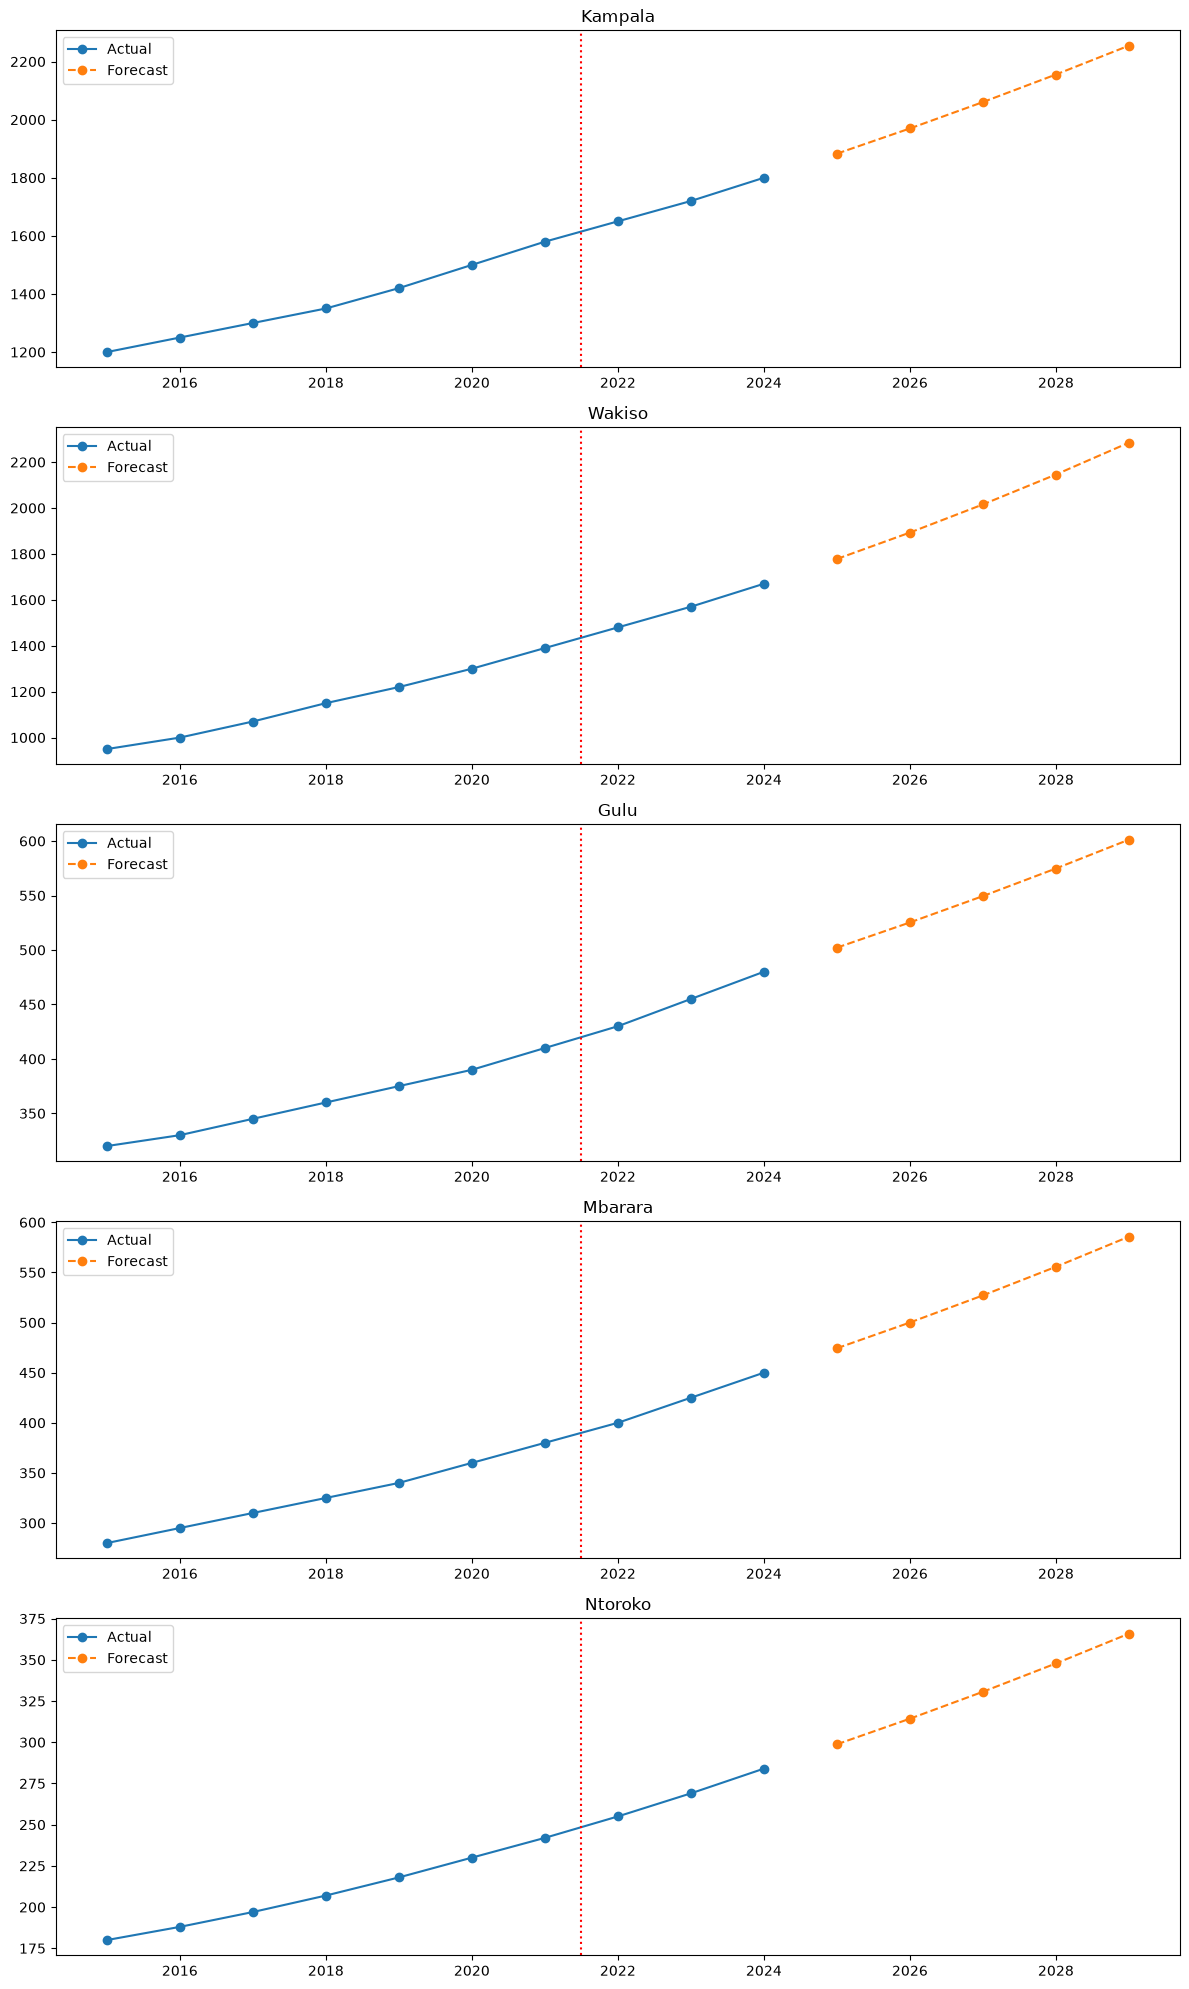

In [12]:
fig, axes = plt.subplots(
    5,
    1,
    figsize=(12,20)
)

for ax, district in zip(axes, districts):

    ax.plot(
        years,
        district.populations,
        marker="o",
        label="Actual"
    )

    future_years = np.arange(
        2025,
        2030
    )

    ax.plot(
        future_years,
        forecast_results[district.name],
        marker="o",
        linestyle="--",
        label="Forecast"
    )

    ax.axvline(
        2021.5,
        color="red",
        linestyle=":"
    )

    ax.set_title(
        district.name
    )

    ax.legend()

plt.tight_layout()
plt.show()

In [13]:
planning = []

for district in districts:

    current_pop = district.populations[-1]

    future_pop = forecast_results[
        district.name
    ][-1]

    current_rooms = math.ceil(
        (current_pop * 0.18) / 53
    )

    future_rooms = math.ceil(
        (future_pop * 0.18) / 53
    )

    planning.append({
        "District": district.name,
        "Additional Classrooms":
        future_rooms - current_rooms
    })

pd.DataFrame(planning)

,District,Additional Classrooms
0,Kampala,1
1,Wakiso,2
2,Gulu,1
3,Mbarara,0
4,Ntoroko,1


# Findings and Limitations

The analysis showed positive population growth across all selected districts. Based on CAGR values, some districts are growing faster than others, indicating increasing demand for social services and educational infrastructure. The validation exercise demonstrated that forecasting accuracy differs across districts and models. Linear and exponential models generally provide more stable and realistic forecasts because they are based on long-term trends observed in the historical data. The Fibonacci-ratio model tends to generate very rapid growth and can easily overestimate future populations when applied repeatedly over several forecast periods.

Forecast variance was generally lower than historical variance for the better-performing models, suggesting smoother forecasts and reduced year-to-year fluctuations. This makes the forecasts easier to use for planning purposes. The classroom estimation exercise showed that all districts will require additional classrooms by 2029 if population growth continues, emphasizing the importance of long-term educational planning.

Several limitations should be noted. First, the dataset contains only ten years of observations, limiting the ability to capture structural changes and long-term demographic dynamics. Second, the population figures are illustrative and do not represent official census estimates. Third, population forecasting assumes that historical growth patterns continue into the future, which may not occur due to migration, economic change, disease outbreaks, policy interventions, or environmental shocks. Therefore, the forecasts should be interpreted as planning scenarios rather than exact predictions.